In [ ]:
import pandas as pd

In [ ]:
df = pd.read_excel("ssra dataset.xlsx")
df.head(20)

,PAYMENT DATE,REFERENCE NUMBER,INVOICE NUMBER,TYPE,TIN,NAME,CURRENCY,AMOUNT PAID,STATUS
0,31-12-2025,ETAXBQRHGGH366B8,LNKZVKD,tax_return,B20211102VDMGM4,UGANDA NATIONAL AIRLINES COMPANY LIMITED,USD,360.0,0
1,31-12-2025,ETAXD3HQN3PB4B4Q,EZEBXEN,tax_return,B20211102VDMGM4,UGANDA NATIONAL AIRLINES COMPANY LIMITED,USD,360.0,0
2,31-12-2025,ETAXRRPMLDJDBFQR,NGKMNKG,tax_return,B20211102VDMGM4,UGANDA NATIONAL AIRLINES COMPANY LIMITED,USD,360.0,0
3,31-12-2025,ETAXD82QJRBLN4FJ,LNKQQMV,tax_return,B20220804VWX8LX,GREEN SOM GENERAL TRADING COMPANY LIMITED,SSP,1161000.0,0
4,31-12-2025,EXVXWN,KDGWZW,tax_return,B20220804VWX8LX,GREEN SON GENERAL TRADING COMPANY LIMITED,SSP,34000.0,1
5,31-12-2025,ETAXQQ6DJG7BRRDG,JAPWQQA,tax_return,B20220804VWX8LX,GREEN SOM GENERAL TRADING COMPANY LIMITED,SSP,170000.0,0
6,31-12-2025,ETAXFNQPL2GPB2ND,QXRBBLK,tax_return,B20220804VWX8LX,GREEN SOM GENERAL TRADING COMPANY LIMITED,SSP,1563966.0,0
7,31-12-2025,ETAXGF6N3HMPJMGD,YGLXXWM,tax_return,B20220804VWX8LX,GREEN SOM GENERAL TRADING COMPANY LIMITED,SSP,1593900.0,0
8,31-12-2025,ETAXTN9MD6NRRJPQ,JAPWQQP,tax_return,B20220804VWX8LX,GREEN SOM GENERAL TRADING COMPANY LIMITED,SSP,100000.0,1
9,31-12-2025,GLBLNY,NDGXZV,tax_return,B20220804VWX8LX,GREEN SON GENERAL TRADING COMPANY LIMITED,SSP,34000.0,1


AGGREGATION OF TAXPAYERS

In [ ]:
df = pd.get_dummies(df, columns=["CURRENCY"], drop_first=True)
df.head()

,PAYMENT DATE,REFERENCE NUMBER,INVOICE NUMBER,TYPE,TIN,NAME,AMOUNT PAID,STATUS,CURRENCY_USD
0,31-12-2025,ETAXBQRHGGH366B8,LNKZVKD,tax_return,B20211102VDMGM4,UGANDA NATIONAL AIRLINES COMPANY LIMITED,360.0,0,True
1,31-12-2025,ETAXD3HQN3PB4B4Q,EZEBXEN,tax_return,B20211102VDMGM4,UGANDA NATIONAL AIRLINES COMPANY LIMITED,360.0,0,True
2,31-12-2025,ETAXRRPMLDJDBFQR,NGKMNKG,tax_return,B20211102VDMGM4,UGANDA NATIONAL AIRLINES COMPANY LIMITED,360.0,0,True
3,31-12-2025,ETAXD82QJRBLN4FJ,LNKQQMV,tax_return,B20220804VWX8LX,GREEN SOM GENERAL TRADING COMPANY LIMITED,1161000.0,0,False
4,31-12-2025,EXVXWN,KDGWZW,tax_return,B20220804VWX8LX,GREEN SON GENERAL TRADING COMPANY LIMITED,34000.0,1,False


In [ ]:
taxpayer_agg = (
    df.groupby("TIN")
      .agg(
          total_payments = ("AMOUNT PAID", "count"),
          total_amount_paid = ("AMOUNT PAID", "sum"),
          avg_payment_amount = ("AMOUNT PAID", "mean"),
          max_payment_amount = ("AMOUNT PAID", "max"),
          min_payment_amount = ("AMOUNT PAID", "min"),
          std_payment_amount = ("AMOUNT PAID", "std"),

          usd_payment_ratio = ("CURRENCY_USD", "mean"),

          risky_payment_count = ("STATUS", "sum"),
          risky_payment_ratio = ("STATUS", "mean")
      )
      .reset_index()
)


PAYMENT VARIATION FOR STABILITY PURPOSES

In [ ]:
taxpayer_agg["payment_variation_ratio"] = (
    taxpayer_agg["std_payment_amount"] / taxpayer_agg["avg_payment_amount"]
)


RISK DOMINANCE FLAG

In [ ]:
taxpayer_agg["high_risk_taxpayer"] = (
    taxpayer_agg["risky_payment_ratio"] > 0.5
).astype(int)


MAKING SURE DATES ARE IN THE DATE FORMAT SINCE THEY WILL BE USED TO TELL HOW ACITVE THE TAXPAYERS ARE.

In [ ]:
df["PAYMENT DATE"] = pd.to_datetime(df["PAYMENT DATE"], errors="coerce")

date_features = (
    df.groupby("TIN")
      .agg(
          first_payment_date = ("PAYMENT DATE", "min"),
          last_payment_date = ("PAYMENT DATE", "max")
      )
      .reset_index()
)

date_features["active_days"] = (
    date_features["last_payment_date"] - date_features["first_payment_date"]
).dt.days


/tmp/ipykernel_524/902351114.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["PAYMENT DATE"] = pd.to_datetime(df["PAYMENT DATE"], errors="coerce")


In [ ]:
taxpayer_agg = taxpayer_agg.merge(date_features, on="TIN", how="left")


In [ ]:
taxpayer_agg.head()
taxpayer_agg.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1487 entries, 0 to 1486
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   TIN                      1487 non-null   object        
 1   total_payments           1487 non-null   int64         
 2   total_amount_paid        1487 non-null   float64       
 3   avg_payment_amount       1487 non-null   float64       
 4   max_payment_amount       1487 non-null   float64       
 5   min_payment_amount       1487 non-null   float64       
 6   std_payment_amount       1214 non-null   float64       
 7   usd_payment_ratio        1487 non-null   float64       
 8   risky_payment_count      1487 non-null   int64         
 9   risky_payment_ratio      1487 non-null   float64       
 10  payment_variation_ratio  1214 non-null   float64       
 11  high_risk_taxpayer       1487 non-null   int64         
 12  first_payment_date       1487 non-

NaNs in std_payment_amount and payment_variation_ratio need to be fixed

In [ ]:
for col in ["std_payment_amount", "payment_variation_ratio"]:
    taxpayer_agg[col] = taxpayer_agg[col].fillna(0)


# dropping date
df = taxpayer_agg.drop(columns=["first_payment_date", "last_payment_date"])


In [ ]:
X = df.drop(columns=[
    "TIN",
    "high_risk_taxpayer",
    "risky_payment_ratio",
    "risky_payment_count"
])
y = df["high_risk_taxpayer"]

TRAIN TEST SPLIT NOW

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [ ]:
FEATURE_COLUMNS = [
    "total_payments",
    "total_amount_paid",
    "avg_payment_amount",
    "max_payment_amount",
    "min_payment_amount",
    "std_payment_amount",
    "usd_payment_ratio",
    "payment_variation_ratio",
    "active_days"
]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)




In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="lbfgs"
)
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
import joblib
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

joblib.dump(model, "taxpayer_risk_logreg_v1.pkl")
joblib.dump(scaler, "scaler_v1.pkl")


['scaler_v1.pkl']

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[158  11]
 [ 18 111]]
              precision    recall  f1-score   support

           0       0.90      0.93      0.92       169
           1       0.91      0.86      0.88       129

    accuracy                           0.90       298
   macro avg       0.90      0.90      0.90       298
weighted avg       0.90      0.90      0.90       298



FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/confusion_matrix_taxpayer_model.png'

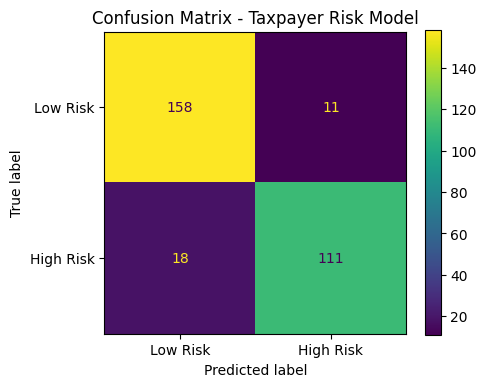

In [ ]:
cm = np.array([[158, 11],
               [18, 111]])

# Chart 1: Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low Risk", "High Risk"])
disp.plot(ax=ax)
plt.title("Confusion Matrix - Taxpayer Risk Model")
plt.tight_layout()
cm_file = "/mnt/data/confusion_matrix_taxpayer_model.png"
plt.savefig(cm_file)
plt.close()

# Chart 2: Performance Metrics
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]
values = [90, 91, 86, 88]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(metrics, values)
ax.set_ylim(0, 100)
ax.set_ylabel("Percentage")
ax.set_title("Model Performance Metrics")
plt.tight_layout()
metrics_file = "/mnt/data/model_performance_metrics.png"
plt.savefig(metrics_file)
plt.close()

print(cm_file)
print(metrics_file)





In [ ]:
# Model metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
scores = [90, 91, 86, 88]

# Create chart
plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, scores)

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.5,
        f'{height}%',
        ha='center'
    )

plt.ylim(0, 100)
plt.ylabel('Percentage (%)')
plt.title('Performance Metrics of the Taxpayer Risk Scoring Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

coefficients = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.coef_[0]
}).sort_values(by="coefficient", ascending=False)

coefficients

Create an evaluation dataframe

In [ ]:
risk_probs = model.predict_proba(X_test_scaled)[:, 1]
df_eval = X_test.copy()
df_eval["true_label"] = y_test.values
df_eval["risk_score"] = risk_probs


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Sort by risk (this is optional but important)

In [ ]:
df_eval = df_eval.sort_values("risk_score", ascending=False)


Decide thresholds (policy step)

In [ ]:
high_cutoff = df_eval["risk_score"].quantile(0.80)
medium_cutoff = df_eval["risk_score"].quantile(0.50)


Assign risk bands

In [ ]:
def risk_band(p):
    if p >= high_cutoff:
        return "HIGH"
    elif p >= medium_cutoff:
        return "MEDIUM"
    else:
        return "LOW"

df_eval["risk_band"] = df_eval["risk_score"].apply(risk_band)
